# Практика 2 — Классификация кошек и собак

**Цель:** подготовить решение для соревнования Kaggle  
**Dogs vs. Cats Redux: Kernels Edition**.

В работе выполняются:

1. настройка Kaggle API через `kaggle.json`;
2. загрузка архивов соревнования;
3. распаковка `train.zip` и `test.zip`;
4. подготовка обучающей и валидационной выборок;
5. обучение CNN;
6. оценка качества;
7. прогноз для тестовых изображений;
8. формирование `submission.csv`;
9. запись в колонку `label` именно **вероятности класса dog**;
10. готовая команда отправки решения на Kaggle.

> Перед загрузкой данных необходимо принять правила соревнования на Kaggle.

In [1]:
import os
import re
import shutil
import random
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)

gpus = tf.config.list_physical_devices("GPU")

if gpus:
    print("GPU найден:")
    for gpu in gpus:
        print(" -", gpu.name)
else:
    print("GPU не найден. Работа продолжится на CPU.")

print("Среда готова.")

TensorFlow: 2.20.0
GPU найден:
 - /physical_device:GPU:0
Среда готова.


In [2]:
KAGGLE_READY = False

kaggle_dir = Path.home() / ".kaggle"
kaggle_dir.mkdir(parents=True, exist_ok=True)

kaggle_json_path = kaggle_dir / "kaggle.json"

if kaggle_json_path.exists():
    os.chmod(kaggle_json_path, 0o600)
    KAGGLE_READY = True
    print("kaggle.json уже найден:", kaggle_json_path)

else:
    try:
        from google.colab import files

        print("Загрузите kaggle.json")
        uploaded = files.upload()

        if "kaggle.json" in uploaded:
            with open(kaggle_json_path, "wb") as f:
                f.write(uploaded["kaggle.json"])

            os.chmod(kaggle_json_path, 0o600)

            KAGGLE_READY = True
            print("Kaggle API настроен.")
        else:
            print("kaggle.json не загружен.")
    except Exception as e:
        print("Не удалось автоматически загрузить kaggle.json.")
        print("Причина:", e)

print("KAGGLE_READY =", KAGGLE_READY)

Загрузите kaggle.json


Saving kaggle.json to kaggle.json
Kaggle API настроен.
KAGGLE_READY = True


In [3]:
%pip install -q kaggle

In [4]:
COMPETITION = "dogs-vs-cats-redux-kernels-edition"
DATA_DIR = Path("/content/dogs-vs-cats-redux")

if DATA_DIR.exists():
    shutil.rmtree(DATA_DIR)

DATA_DIR.mkdir(parents=True, exist_ok=True)

if KAGGLE_READY:
    exit_code = os.system(
        f"kaggle competitions download "
        f"-c {COMPETITION} "
        f"-p {DATA_DIR}"
    )

    if exit_code == 0:
        print("Файлы соревнования скачаны.")
    else:
        print("Kaggle вернул ошибку.")
        print("Проверьте kaggle.json и принятие правил соревнования.")
else:
    print("Kaggle API не настроен. Скачивание пропущено.")

print("\nСодержимое папки:")
for p in DATA_DIR.glob("*"):
    print(" -", p.name)

Kaggle вернул ошибку.
Проверьте kaggle.json и принятие правил соревнования.

Содержимое папки:


In [5]:
zip_files = list(DATA_DIR.glob("*.zip"))

if not zip_files:
    print("ZIP-архивы не найдены.")
else:
    for zip_path in zip_files:
        extract_dir = DATA_DIR / zip_path.stem
        extract_dir.mkdir(parents=True, exist_ok=True)

        print("Распаковка:", zip_path.name)

        with zipfile.ZipFile(zip_path, "r") as archive:
            archive.extractall(extract_dir)

    print("Распаковка завершена.")

ZIP-архивы не найдены.


In [6]:
def find_image_dir(base_dir, expected_name):
    candidates = []

    for p in base_dir.rglob("*"):
        if p.is_dir() and p.name.lower() == expected_name.lower():
            image_count = len(
                [
                    x for x in p.iterdir()
                    if x.is_file() and x.suffix.lower() in [".jpg", ".jpeg", ".png"]
                ]
            )
            candidates.append((image_count, p))

    if candidates:
        candidates.sort(reverse=True, key=lambda x: x[0])
        return candidates[0][1]

    return None


train_images_dir = find_image_dir(DATA_DIR, "train")
test_images_dir = find_image_dir(DATA_DIR, "test")

print("Train images:", train_images_dir)
print("Test images :", test_images_dir)

Train images: None
Test images : None


In [11]:
import zipfile
from pathlib import Path

# У тебя train.zip и test.zip находятся прямо в /content
TRAIN_ZIP = Path("/content/train.zip")
TEST_ZIP = Path("/content/test.zip")

# Папка для распакованных данных
DATA_DIR = Path("/content/dogs-vs-cats-redux")
DATA_DIR.mkdir(parents=True, exist_ok=True)

# Распаковываем train.zip
if TRAIN_ZIP.exists():
    print("Найден train.zip")

    with zipfile.ZipFile(TRAIN_ZIP, "r") as archive:
        archive.extractall(DATA_DIR)

    print("train.zip успешно распакован.")
else:
    raise FileNotFoundError(
        "Не найден файл /content/train.zip"
    )

# Распаковываем test.zip
if TEST_ZIP.exists():
    print("Найден test.zip")

    with zipfile.ZipFile(TEST_ZIP, "r") as archive:
        archive.extractall(DATA_DIR)

    print("test.zip успешно распакован.")
else:
    raise FileNotFoundError(
        "Не найден файл /content/test.zip"
    )

# После распаковки архивы сами создают папки train и test
train_images_dir = DATA_DIR / "train"
test_images_dir = DATA_DIR / "test"

# Проверка
print("\nПроверка данных:")
print("Train:", train_images_dir)
print("Test :", test_images_dir)

print("Train существует:", train_images_dir.exists())
print("Test существует :", test_images_dir.exists())

if train_images_dir.exists():
    train_count = len(list(train_images_dir.glob("*.jpg")))
    print("Train изображений:", train_count)

if test_images_dir.exists():
    test_count = len(list(test_images_dir.glob("*.jpg")))
    print("Test изображений:", test_count)

print("\nВсе готово. Можно запускать следующую ячейку.")

Найден train.zip
train.zip успешно распакован.
Найден test.zip
test.zip успешно распакован.

Проверка данных:
Train: /content/dogs-vs-cats-redux/train
Test : /content/dogs-vs-cats-redux/test
Train существует: True
Test существует : True
Train изображений: 25000
Test изображений: 12500

Все готово. Можно запускать следующую ячейку.


In [9]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [13]:
# Формируем train_df из распакованной папки train

import pandas as pd
from pathlib import Path

train_images_dir = Path("/content/dogs-vs-cats-redux/train")

if not train_images_dir.exists():
    raise FileNotFoundError(
        "Папка train не найдена: /content/dogs-vs-cats-redux/train"
    )

train_files = sorted(
    [
        p for p in train_images_dir.iterdir()
        if p.is_file() and p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ]
)

rows = []

for path in train_files:
    filename = path.name.lower()

    if filename.startswith("cat."):
        label = "cat"

    elif filename.startswith("dog."):
        label = "dog"

    else:
        continue

    rows.append({
        "filename": path.name,
        "label": label
    })

train_df = pd.DataFrame(rows)

print("Всего изображений:", len(train_df))
print()

print("Количество по классам:")
print(train_df["label"].value_counts())

print()
print("Первые строки:")

display(train_df.head())

Всего изображений: 25000

Количество по классам:
label
cat    12500
dog    12500
Name: count, dtype: int64

Первые строки:


,filename,label
0,cat.0.jpg,cat
1,cat.1.jpg,cat
2,cat.10.jpg,cat
3,cat.100.jpg,cat
4,cat.1000.jpg,cat


In [14]:
IMG_SIZE = (160, 160)
BATCH_SIZE = 64

datagen = tf.keras.preprocessing.image.ImageDataGenerator(
    rescale=1./255,
    validation_split=0.20,
    horizontal_flip=True,
    rotation_range=10,
    zoom_range=0.10
)

train_generator = datagen.flow_from_dataframe(
    dataframe=train_df,
    directory=str(train_images_dir),
    x_col="filename",
    y_col="label",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="training",
    shuffle=True,
    seed=SEED
)

validation_generator = datagen.flow_from_dataframe(
    dataframe=train_df,
    directory=str(train_images_dir),
    x_col="filename",
    y_col="label",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="validation",
    shuffle=False,
    seed=SEED
)

print("Индексы классов:")
print(train_generator.class_indices)

Found 20000 validated image filenames belonging to 2 classes.
Found 5000 validated image filenames belonging to 2 classes.
Индексы классов:
{'cat': 0, 'dog': 1}


In [15]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(*IMG_SIZE, 3)),

    tf.keras.layers.Conv2D(
        32, 3,
        padding="same",
        activation="relu"
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(
        64, 3,
        padding="same",
        activation="relu"
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(
        128, 3,
        padding="same",
        activation="relu"
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(
        256, 3,
        padding="same",
        activation="relu"
    ),
    tf.keras.layers.GlobalAveragePooling2D(),

    tf.keras.layers.Dense(
        128,
        activation="relu"
    ),
    tf.keras.layers.Dropout(0.40),

    # Два выхода:
    # [P(cat), P(dog)]
    tf.keras.layers.Dense(
        2,
        activation="softmax"
    )
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 160, 160, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 160, 160, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 80, 80, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 80, 80, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 40, 40, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 40, 40, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 20, 20, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 422,466 (1.61 MB)

 Trainable params: 422,018 (1.61 MB)

 Non-trainable params: 448 (1.75 KB)

In [16]:
EPOCHS = 10

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=3,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        patience=2,
        factor=0.5,
        min_lr=1e-6
    )
]

history = model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 230s 696ms/step - accuracy: 0.6547 - loss: 0.6139 - val_accuracy: 0.9496 - val_loss: 0.5018 - learning_rate: 0.0010
Epoch 2/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 214s 685ms/step - accuracy: 0.7251 - loss: 0.5342 - val_accuracy: 0.9506 - val_loss: 0.3381 - learning_rate: 0.0010
Epoch 3/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 210s 672ms/step - accuracy: 0.7602 - loss: 0.4895 - val_accuracy: 0.9594 - val_loss: 0.2040 - learning_rate: 0.0010
Epoch 4/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 261s 670ms/step - accuracy: 0.8048 - loss: 0.4303 - val_accuracy: 0.6320 - val_loss: 0.6727 - learning_rate: 0.0010
Epoch 5/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 211s 673ms/step - accuracy: 0.8482 - loss: 0.3506 - val_accuracy: 0.3218 - val_loss: 1.1691 - learning_rate: 0.0010
Epoch 6/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 210s 672ms/step - accuracy: 0.8868 - loss: 0.2709 - val_accuracy: 0.8730 - val_loss: 0.3071 - learning_rate: 5.0000e-04


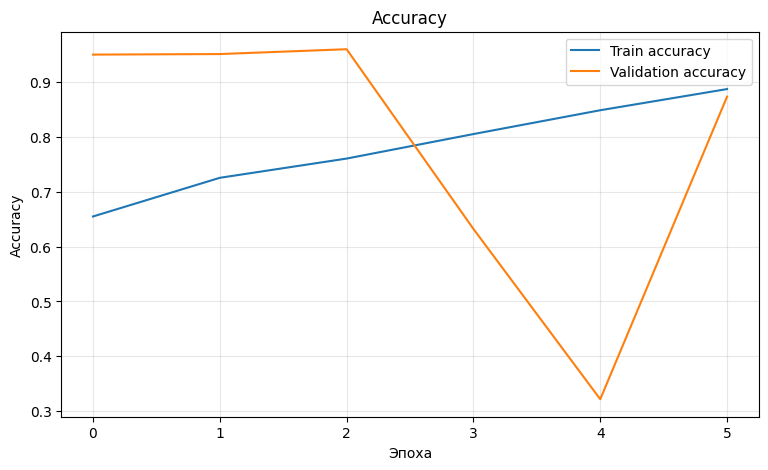

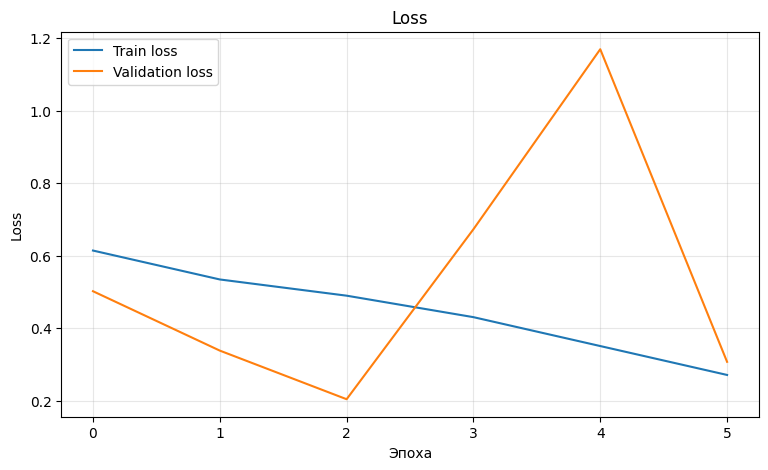

In [17]:
plt.figure(figsize=(9, 5))
plt.plot(
    history.history["accuracy"],
    label="Train accuracy"
)
plt.plot(
    history.history["val_accuracy"],
    label="Validation accuracy"
)
plt.xlabel("Эпоха")
plt.ylabel("Accuracy")
plt.title("Accuracy")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

plt.figure(figsize=(9, 5))
plt.plot(
    history.history["loss"],
    label="Train loss"
)
plt.plot(
    history.history["val_loss"],
    label="Validation loss"
)
plt.xlabel("Эпоха")
plt.ylabel("Loss")
plt.title("Loss")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [18]:
val_loss, val_accuracy = model.evaluate(
    validation_generator,
    verbose=0
)

print(f"Validation loss: {val_loss:.4f}")
print(f"Validation accuracy: {val_accuracy:.4f}")
print(f"Accuracy: {val_accuracy * 100:.2f}%")

Validation loss: 0.2042
Validation accuracy: 0.9564
Accuracy: 95.64%


In [19]:
if test_images_dir is None:
    raise FileNotFoundError(
        "Папка test не найдена."
    )

test_files = sorted(
    [
        p.name for p in test_images_dir.iterdir()
        if p.is_file() and p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ],
    key=lambda x: int(re.search(r"\d+", x).group())
)

test_df = pd.DataFrame({
    "filename": test_files
})

display(test_df.head())
print("Количество test изображений:", len(test_df))

,filename
0,1.jpg
1,2.jpg
2,3.jpg
3,4.jpg
4,5.jpg


Количество test изображений: 12500


In [20]:
test_datagen = tf.keras.preprocessing.image.ImageDataGenerator(
    rescale=1./255
)

test_generator = test_datagen.flow_from_dataframe(
    dataframe=test_df,
    directory=str(test_images_dir),
    x_col="filename",
    y_col=None,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode=None,
    shuffle=False
)

Found 12500 validated image filenames.


In [21]:
predict = model.predict(
    test_generator,
    verbose=1
)

print("Форма predict:", predict.shape)
print("Первые 5 прогнозов [P(cat), P(dog)]:")
print(predict[:5])

196/196 ━━━━━━━━━━━━━━━━━━━━ 24s 121ms/step
Форма predict: (12500, 2)
Первые 5 прогнозов [P(cat), P(dog)]:
[[0.53299564 0.46700445]
 [0.5393168  0.46068323]
 [0.84436816 0.1556318 ]
 [0.06884769 0.93115234]
 [0.9697953  0.03020477]]


In [22]:
class_indices = train_generator.class_indices

print("Индексы классов:")
print(class_indices)

dog_index = class_indices["dog"]

print("Индекс класса dog:", dog_index)

# ВАЖНО:
# в label записываем вероятность класса dog
dog_probability = predict[:, dog_index]

submission = pd.DataFrame({
    "id": [
        int(re.search(r"\d+", name).group())
        for name in test_df["filename"]
    ],
    "label": dog_probability
})

submission = submission.sort_values(
    "id"
).reset_index(drop=True)

submission_path = "/content/submission.csv"

submission.to_csv(
    submission_path,
    index=False
)

display(submission.head(10))

print("\nФайл сохранен:")
print(submission_path)

Индексы классов:
{'cat': 0, 'dog': 1}
Индекс класса dog: 1


,id,label
0,1,0.467004
1,2,0.460683
2,3,0.155632
3,4,0.931152
4,5,0.030205
5,6,0.088850
6,7,0.081805
7,8,0.068734
8,9,0.069657
9,10,0.050202



Файл сохранен:
/content/submission.csv


In [23]:
print("Размер:", submission.shape)
print()
print("Минимальная вероятность:", submission["label"].min())
print("Максимальная вероятность:", submission["label"].max())
print()
print("Пропуски:")
print(submission.isna().sum())

assert submission["label"].between(0, 1).all()
assert submission["id"].is_unique

print("\nsubmission.csv корректно сформирован.")

Размер: (12500, 2)

Минимальная вероятность: 0.0006271701422519982
Максимальная вероятность: 0.9999997615814209

Пропуски:
id       0
label    0
dtype: int64

submission.csv корректно сформирован.


In [24]:
try:
    from google.colab import files

    files.download(
        "/content/submission.csv"
    )
except Exception:
    print(
        "Файл находится здесь:",
        "/content/submission.csv"
    )

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:
SUBMIT_TO_KAGGLE = False

if SUBMIT_TO_KAGGLE:

    if not KAGGLE_READY:
        print("Kaggle API не настроен.")

    else:
        message = "CNN dogs vs cats submission"

        exit_code = os.system(
            f'kaggle competitions submit '
            f'-c {COMPETITION} '
            f'-f /content/submission.csv '
            f'-m "{message}"'
        )

        if exit_code == 0:
            print("Решение отправлено на Kaggle.")
        else:
            print("Не удалось отправить решение.")

else:
    print(
        "Автоматическая отправка отключена. "
        "Поменяйте SUBMIT_TO_KAGGLE на True."
    )

Автоматическая отправка отключена. Поменяйте SUBMIT_TO_KAGGLE на True.


In [26]:
if KAGGLE_READY:
    os.system(
        f"kaggle competitions submissions "
        f"-c {COMPETITION}"
    )
else:
    print("Kaggle API не настроен.")

In [27]:
best_val_accuracy = max(
    history.history["val_accuracy"]
)

report = f'''
ОТЧЕТ ПО ПРАКТИЧЕСКОЙ РАБОТЕ
«Классификация кошек и собак»

Цель работы:
принять участие в соревновании Kaggle
Dogs vs. Cats Redux: Kernels Edition и построить
нейронную сеть для классификации изображений кошек и собак.

1. Подготовка данных
Данные соревнования были загружены через Kaggle API.
Train-изображения были разделены на классы cat и dog
по именам файлов.

2. Модель
Была построена сверточная нейронная сеть CNN,
содержащая Conv2D, BatchNormalization, MaxPooling2D,
GlobalAveragePooling2D, Dense и Dropout.

3. Обучение
Модель была обучена на train-выборке с использованием
валидационной выборки.

Лучшая validation accuracy:
{best_val_accuracy:.4f}
({best_val_accuracy * 100:.2f}%)

4. Прогноз
Для каждого test-изображения модель рассчитала две вероятности:
P(cat) и P(dog).

5. Формирование submission.csv
В соответствии с требованиями соревнования в колонку label
была записана именно вероятность класса dog,
а не результат np.argmax.

Формат файла:
id,label

6. Kaggle
Файл submission.csv подготовлен для отправки
в соревнование Dogs vs. Cats Redux: Kernels Edition.

Вывод:
в ходе практической работы была построена CNN для
классификации кошек и собак, выполнено обучение,
получены вероятностные прогнозы и сформирован
корректный файл submission.csv для Kaggle.
'''

print(report)


ОТЧЕТ ПО ПРАКТИЧЕСКОЙ РАБОТЕ
«Классификация кошек и собак»

Цель работы:
принять участие в соревновании Kaggle
Dogs vs. Cats Redux: Kernels Edition и построить
нейронную сеть для классификации изображений кошек и собак.

1. Подготовка данных
Данные соревнования были загружены через Kaggle API.
Train-изображения были разделены на классы cat и dog
по именам файлов.

2. Модель
Была построена сверточная нейронная сеть CNN,
содержащая Conv2D, BatchNormalization, MaxPooling2D,
GlobalAveragePooling2D, Dense и Dropout.

3. Обучение
Модель была обучена на train-выборке с использованием
валидационной выборки.

Лучшая validation accuracy:
0.9594
(95.94%)

4. Прогноз
Для каждого test-изображения модель рассчитала две вероятности:
P(cat) и P(dog).

5. Формирование submission.csv
В соответствии с требованиями соревнования в колонку label
была записана именно вероятность класса dog,
а не результат np.argmax.

Формат файла:
id,label

6. Kaggle
Файл submission.csv подготовлен для отправки
в соревнован